# COURSE NAME: DATA MINING, MODELING AND ANALYTICS

# Assignment 1
# BY NANFUKA FATUMA
# B36106

# Project 1— Bank marketing

**Task:** Predicting term-deposit subscription to support selection of customers for a telephone campaign.

All modelling uses a fixed random seed.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve, brier_score_loss, mean_absolute_error, mean_squared_error, r2_score)
SEED=42
pd.set_option('display.max_columns',40)

## Question 1. Explore the data, prepare it with justification, and establish a majority-class baseline

I first examine the dataset's size, variable types, class balance, missingness, and recorded `unknown` categories. The outcome is `y` (`yes`/`no`). The prediction must be available **before a call**, so I remove `duration`: its value is recorded during or after the call and would leak future information into a pre-contact decision. I retain the other campaign-history fields, but recognise that they may not be available for all future customer lists. I preserve `unknown` as an observed category rather than silently treating it as a numerical missing value.

I use a stratified 60% training, 20% validation and 20% test split. All transformations are fitted only on the training partition. I establish a majority-class baseline, and report accuracy alongside minority-class recall and average precision because the subscription class is uncommon.

Shape: (41188, 21) | Exact duplicate rows: 12
Missing cells: 0
Outcome distribution:
     count  percent
y                  
no   36548    88.73
yes   4640    11.27
Data types:
object     11
int64       5
float64     5
Unknown-category counts:
default      8597
education    1731
housing       990
loan          990
job           330
marital        80
Numeric summary:
            age  duration  campaign     pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
count  41188.00  41188.00  41188.00  41188.00  41188.00      41188.00        41188.00       41188.00   41188.00     41188.00
mean      40.02    258.29      2.57    962.48      0.17          0.08           93.58         -40.50       3.62      5167.04
std       10.42    259.28      2.77    186.91      0.49          1.57            0.58           4.63       1.73        72.25
min       17.00      0.00      1.00      0.00      0.00         -3.40           92.20         -50.80       0.63      4963.60
25%   

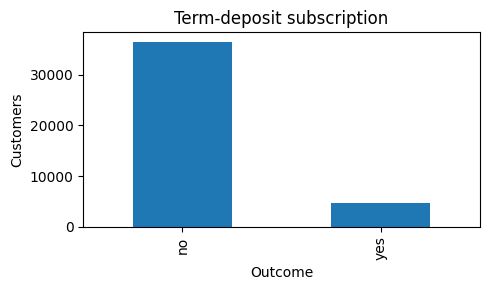

Split sizes: 24712 8238 8238 | Predictor counts: 9 numeric, 10 categorical
Validation majority baseline — accuracy 0.8874 | recall 0.0000 | balanced accuracy 0.5000 | average precision 0.1126


In [ ]:
bank=pd.read_csv('data/bank-additional-full.csv',sep=';')
print('Shape:',bank.shape,'| Exact duplicate rows:',bank.duplicated().sum())
print('Missing cells:',int(bank.isna().sum().sum()))
print('Outcome distribution:');print(bank.y.value_counts().to_frame('count').assign(percent=lambda d:100*d['count']/len(bank)).round(2).to_string())
print('Data types:');print(bank.dtypes.value_counts().to_string())
print('Unknown-category counts:');print((bank.select_dtypes('object')=='unknown').sum().loc[lambda x:x>0].sort_values(ascending=False).to_string())
print('Numeric summary:');print(bank.describe().round(2).to_string())
fig,ax=plt.subplots(figsize=(5,3));bank.y.value_counts().plot.bar(ax=ax);ax.set(title='Term-deposit subscription',ylabel='Customers',xlabel='Outcome');plt.tight_layout();plt.show()
X=bank.drop(columns=['y','duration']);y=bank.y.eq('yes').astype(int)
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,stratify=y_dev,random_state=SEED)
cat=X.select_dtypes(include='object').columns.tolist();num=X.select_dtypes(exclude='object').columns.tolist()
print('Split sizes:',len(X_train),len(X_val),len(X_test),'| Predictor counts:',len(num),'numeric,',len(cat),'categorical')
base=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
base_pred=base.predict(X_val);base_prob=base.predict_proba(X_val)[:,1]
print('Validation majority baseline — accuracy %.4f | recall %.4f | balanced accuracy %.4f | average precision %.4f'%(accuracy_score(y_val,base_pred),recall_score(y_val,base_pred,zero_division=0),balanced_accuracy_score(y_val,base_pred),average_precision_score(y_val,base_prob)))

## Question 2. Select and rank at most three approaches, with supporting evidence

I compare **regularised logistic regression**, **random forest**, and **histogram gradient boosting**. Logistic regression provides an interpretable linear benchmark; the two tree-based methods capture nonlinearities and interactions. I select the leading model using **validation average precision (AP)**, which measures ranking quality for an imbalanced positive class. ROC AUC and Brier score provide complementary discrimination and probability-quality checks. I do not use the test set to rank models.

Numerical inputs are median-imputed and scaled for logistic regression; categorical inputs are one-hot encoded. The same encoded features are used for random forest. Histogram gradient boosting receives ordinal-coded categories (with an explicit unknown value) and missing-value handling; the codes are not interpreted as meaningful order. These preprocessing steps are fitted inside each pipeline.

Validation model ranking (higher AP is better):
 Rank               Model  Validation AP  Validation ROC AUC  Validation Brier
    1       Random forest         0.4689              0.8010            0.0771
    2   Gradient boosting         0.4607              0.8056            0.0777
    3 Logistic regression         0.4414              0.7971            0.1657
AP reference for a constant prevalence score: 0.1126
Selected model: Random forest


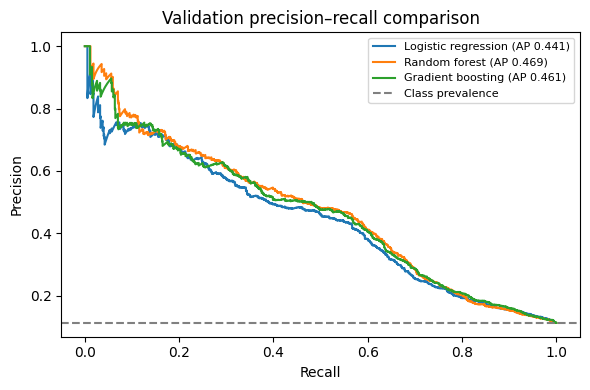

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
linear_pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('category',OneHotEncoder(handle_unknown='ignore'),cat)])
tree_pre=ColumnTransformer([('numeric',SimpleImputer(strategy='median'),num),('category',OneHotEncoder(handle_unknown='ignore'),cat)])
hgb_pre=ColumnTransformer([('numeric',SimpleImputer(strategy='median'),num),('category',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat)])
models={'Logistic regression':Pipeline([('pre',linear_pre),('model',LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED))]),'Random forest':Pipeline([('pre',tree_pre),('model',RandomForestClassifier(n_estimators=180,min_samples_leaf=8,max_features='sqrt',n_jobs=-1,random_state=SEED))]),'Gradient boosting':Pipeline([('pre',hgb_pre),('model',HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=15,l2_regularization=3,random_state=SEED))])}
rows=[];fitted={}
for name,model in models.items():
 model.fit(X_train,y_train);p=model.predict_proba(X_val)[:,1];fitted[name]=model
 rows.append({'Model':name,'Validation AP':average_precision_score(y_val,p),'Validation ROC AUC':roc_auc_score(y_val,p),'Validation Brier':brier_score_loss(y_val,p)})
ranking=pd.DataFrame(rows).sort_values('Validation AP',ascending=False).reset_index(drop=True)
ranking.insert(0,'Rank',np.arange(1,len(ranking)+1))
print('Validation model ranking (higher AP is better):');print(ranking.round(4).to_string(index=False))
print('AP reference for a constant prevalence score: %.4f'%y_val.mean())
chosen=ranking.iloc[0]['Model'];best=fitted[chosen];val_prob=best.predict_proba(X_val)[:,1]
print('Selected model:',chosen)
plt.figure(figsize=(6,4))
for name,model in fitted.items():
 p=model.predict_proba(X_val)[:,1];pr,re,_=precision_recall_curve(y_val,p);plt.plot(re,pr,label='%s (AP %.3f)'%(name,average_precision_score(y_val,p)))
plt.axhline(y_val.mean(),linestyle='--',color='gray',label='Class prevalence');plt.xlabel('Recall');plt.ylabel('Precision');plt.title('Validation precision–recall comparison');plt.legend(fontsize=8);plt.tight_layout();plt.show()

## Question 3. Recommend a decision threshold and explain unnecessary calls versus missed subscribers

I used a **20% calling-capacity scenario** as an explicit operational assumption, not as a bank-provided cost estimate. The decision threshold is the validation-score cutoff selecting approximately the highest-scoring fifth of customers. I compare this policy with thresholds of 0.10, 0.30, and 0.50, and report the number of contacts, false-positive calls, and missed subscribers. In a deployment with a different budget, I would revisit the capacity assumption or maximise expected utility using documented call costs and subscription value.

The final test set is evaluated **once** after the model and capacity policy have been fixed on validation data. A false positive represents a customer called who does not subscribe; a false negative represents a potential subscriber not selected. Neither quantity directly measures incremental campaign lift: the historical labels reflect past contact and selection practices.

In [ ]:
capacity=.20
threshold=float(np.quantile(val_prob,1-capacity))
def policy_table(y_true,prob,thresholds):
 out=[]
 for label,t in thresholds.items():
  pred=(prob>=t).astype(int);tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
  out.append({'Policy':label,'Threshold':t,'Calls':int(pred.sum()),'Call rate':pred.mean(),'Unnecessary calls (FP)':int(fp),'Missed subscribers (FN)':int(fn),'Subscribers reached (TP)':int(tp),'Precision':precision_score(y_true,pred,zero_division=0),'Recall':recall_score(y_true,pred,zero_division=0)})
 return pd.DataFrame(out)
print('Validation threshold comparison:')
print(policy_table(y_val,val_prob,{'0.10':.10,'0.30':.30,'0.50':.50,'Top 20%':threshold}).round(3).to_string(index=False))
print('Recommended score cutoff:',round(threshold,5))
test_prob=best.predict_proba(X_test)[:,1]
print('FINAL HELD-OUT TEST | Model:',chosen)
print('ROC AUC %.4f | AP %.4f | Brier %.4f'%(roc_auc_score(y_test,test_prob),average_precision_score(y_test,test_prob),brier_score_loss(y_test,test_prob)))
print(policy_table(y_test,test_prob,{'Recommended top-20% validation cutoff':threshold}).round(4).to_string(index=False))
print('Baseline test accuracy: %.4f'%accuracy_score(y_test,base.predict(X_test)))
print('Test prevalence: %.4f'%y_test.mean())

Validation threshold comparison:
 Policy  Threshold  Calls  Call rate  Unnecessary calls (FP)  Missed subscribers (FN)  Subscribers reached (TP)  Precision  Recall
   0.10      0.100   1923      0.233                    1299                      304                       624      0.324   0.672
   0.30      0.300    955      0.116                     494                      467                       461      0.483   0.497
   0.50      0.500    338      0.041                     115                      705                       223      0.660   0.240
Top 20%      0.116   1648      0.200                    1052                      332                       596      0.362   0.642
Recommended score cutoff: 0.11625
FINAL HELD-OUT TEST | Model: Random forest
ROC AUC 0.8084 | AP 0.4855 | Brier 0.0748
                               Policy  Threshold  Calls  Call rate  Unnecessary calls (FP)  Missed subscribers (FN)  Subscribers reached (TP)  Precision  Recall
Recommended top-20% validation c

### Interpretation, sensitivity and responsible application

I recommend the **validation-derived top-20% cutoff** only under the stated capacity constraint. Lowering the threshold generally increases recall and the number of unnecessary calls; raising it reduces calls but misses more subscribers. I therefore treat the threshold as a resource-allocation policy rather than an intrinsic property of the model.

The dataset describes historical Portuguese banking campaigns, not a randomised experiment. It cannot establish that calling a high-scoring customer *causes* a subscription. The analysis also lacks explicit call costs, customer lifetime value, contact consent, and prospective drift information. Before operational use, I would test the policy prospectively, monitor performance across relevant customer groups, respect applicable privacy and marketing rules, and recalibrate as campaign conditions change.

**References:** Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001; Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432